In [1]:
from uq_physicell.model_analysis import calculate_qoi_from_db_file
from uq_physicell.database.utils import download_file

db_file = 'ex10_uq_Simulations_OAT_CoCulture.db'
# Download the dataset from zenodo
download_file(db_file)

# df_cell → cell DataFrame (see ex1 for the full dispatch table)
qoi_funcs = {
    'walltime':    lambda mcds: mcds.get_runtime()
}
# Calculate the QoIs based on the qoi_funcs defined
df_qois = calculate_qoi_from_db_file(db_file, qoi_funcs, n_jobs=10)
last_time = df_qois['time'].max()
df_last_time = df_qois[df_qois['time'] == last_time]
display(df_last_time)

,SampleID,time,ReplicateID,walltime
35,0,10080.0,0,274.983017
36,0,10080.0,1,261.926276
37,0,10080.0,2,296.470678
38,0,10080.0,3,280.652664
39,0,10080.0,4,266.653533
...,...,...,...,...
3555,90,10080.0,0,749.066923
3556,90,10080.0,1,706.452289
3557,90,10080.0,2,685.661421
3558,90,10080.0,3,670.526470


In [2]:
from uq_physicell.model_analysis import load_samples
import pandas as pd

# Fixing mislabel of IC_file in the model constuction, cells_1_to_2.csv -> Tumor:CAF 2:1 and cells_2_to_1.csv -> Tumor:CAF 1:2
dic_IC_labels = {
    'cells_1_to_10.csv': 'Tumor:CAF 1:10',
    'cells_1_to_5.csv': 'Tumor:CAF 1:5',
    'cells_2_to_1.csv': 'Tumor:CAF 1:2',
    'cells_1_to_1.csv': 'Tumor:CAF 1:1',
    'cells_1_to_2.csv': 'Tumor:CAF 2:1',
    'cells_5_to_1.csv': 'Tumor:CAF 5:1',
    'cells_10_to_1.csv': 'Tumor:CAF 10:1'
}
# Normalize the QOIs by the nominal case (row with all rules activated)
dic_parameters = load_samples(db_file)
df_samples_desc = pd.DataFrame.from_dict(dic_parameters, orient='index')
df_samples_desc.index.name = 'SampleID'
df_samples_desc['Inactive_rule'] = df_samples_desc.apply(
    lambda row: next((key for key, value in row.items() if key != 'IC_file' and value == 1), None),
    axis=1
)
# Drop the original parameter columns, keeping only 'IC_file' and 'Inactive_rule'
df_samples_desc = df_samples_desc[['IC_file', 'Inactive_rule']]
dic_rules_names = { 'epi_normal_rule_pressureDcellcycle_inactive': 'Epi. Normal CIP', # Contact inhibition of proliferation in normal epithelial cells
                   'epi_normal_rule_ecmImesenc_normal_inactive': 'EMT Normal cell', # Transition from epithelial to mesenchymal state (EMT) in normal epithelial cells
                   'mesenc_normal_rule_ecmDspeed_inactive': 'Slow down N-MC', # Slow down normal mesenchymal cells (N-MC) by decreasing their speed
                   'mesenc_normal_rule_ecmIspeed_inactive': 'Speed up N-MC', # Speed up normal mesenchymal cells (N-MC) by increasing their speed
                   'mesenc_normal_rule_infsignalDepi_normal_inactive': 'MET Normal cell', # Inhibition of transition from mesenchymal state to epithelial (MET) in normal mesenchymal cells (N-MC)
                   'fib_rule_ecmDspeed_inactive': 'Slow down CAF', # Slow down cancer-associated fibroblasts (CAF) by decreasing their speed
                   'fib_rule_ecmIspeed_inactive': 'Speed up CAF', # Speed up cancer-associated fibroblasts (CAF) by increasing their speed
                   'epi_tumor_rule_pressureDcellcycle_inactive': 'Epi. Tumor CIP', # Contact inhibition of proliferation in tumor epithelial cells
                   'epi_tumor_rule_ecmImesenc_tumor_inactive': 'EMT Tumor cell', # Transition from epithelial to mesenchymal state (EMT) in tumor epithelial cells
                   'mesenc_tumor_rule_ecmDspeed_inactive': 'Slow down TA-MC', # Slow down tumor associated mesenchymal cells (TA-MC) by decreasing their speed
                   'mesenc_tumor_rule_ecmIspeed_inactive': 'Speed up TA-MC', # Speed up tumor associated mesenchymal cells (TA-MC) by increasing their speed
                   'mesenc_tumor_rule_infsignalDepi_tumor_inactive': 'MET Tumor cell', # Inhibition of transition from mesenchymal state to epithelial (MET) in tumor mesenchymal cells
                    }
# Rename the Inactive_rule values based on the dic_rules_names mapping
df_samples_desc['Inactive_rule'] = df_samples_desc['Inactive_rule'].map(dic_rules_names).fillna(df_samples_desc['Inactive_rule'])
df_samples_desc['IC_label'] = df_samples_desc['IC_file'].map(dic_IC_labels)
df_last_time = df_last_time.merge(df_samples_desc, left_on='SampleID', right_index=True)
display(df_last_time)

,SampleID,time,ReplicateID,walltime,IC_file,Inactive_rule,IC_label
35,0,10080.0,0,274.983017,cells_1_to_1.csv,None,Tumor:CAF 1:1
36,0,10080.0,1,261.926276,cells_1_to_1.csv,None,Tumor:CAF 1:1
37,0,10080.0,2,296.470678,cells_1_to_1.csv,None,Tumor:CAF 1:1
38,0,10080.0,3,280.652664,cells_1_to_1.csv,None,Tumor:CAF 1:1
39,0,10080.0,4,266.653533,cells_1_to_1.csv,None,Tumor:CAF 1:1
...,...,...,...,...,...,...,...
3555,90,10080.0,0,749.066923,cells_10_to_1.csv,MET Tumor cell,Tumor:CAF 10:1
3556,90,10080.0,1,706.452289,cells_10_to_1.csv,MET Tumor cell,Tumor:CAF 10:1
3557,90,10080.0,2,685.661421,cells_10_to_1.csv,MET Tumor cell,Tumor:CAF 10:1
3558,90,10080.0,3,670.526470,cells_10_to_1.csv,MET Tumor cell,Tumor:CAF 10:1


Median walltime (min): 4.75461785 minutes
95th Percentile walltime (min): 9.179428476666663 minutes


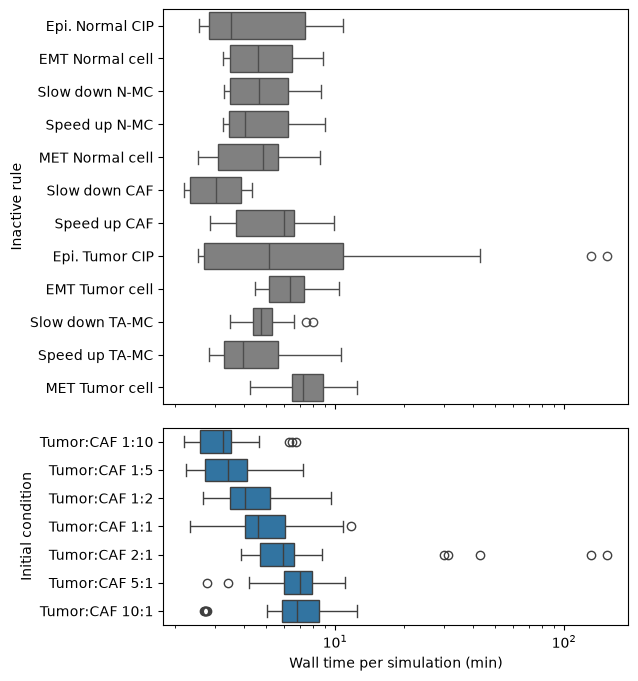

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns
# Convert walltime from seconds to minutes for better readability
df_last_time['walltime (min)'] = df_last_time['walltime'] / 60

fig, ax = plt.subplots(2, 1, figsize=(6, 8), sharex=True,gridspec_kw={'height_ratios': [12, 6], 'hspace': 0.08})
sns.boxplot(data=df_last_time, y='Inactive_rule', x='walltime (min)', log_scale=True, ax=ax[0], color='gray')
ax[0].set(ylabel='Inactive rule')
sns.boxplot(data=df_last_time, y='IC_label', x='walltime (min)', log_scale=True,ax=ax[1], order=dic_IC_labels.values())
ax[1].set(xlabel='Wall time per simulation (min)', ylabel='Initial condition')
plt.savefig('ex10_walltime.svg', format='svg')

print(f"Median walltime (min): {df_last_time['walltime (min)'].median()} minutes")
print(f"95th Percentile walltime (min): {df_last_time['walltime (min)'].quantile(0.95)} minutes")
